# 08 — Thẩm định ảnh và nhãn QPOSD

SOS vẫn là dữ liệu chính. Notebook này kiểm tra nguồn nhãn bổ sung trước khi
huấn luyện hoặc chấm điểm. Không sửa kích thước mask, không tự đoán màu nhãn.
Nguồn: [QPOSD bản 19258036](https://zenodo.org/records/19258036), CC BY 4.0.
Look-alike là lớp chung, chưa có nhãn riêng gió yếu, màng sinh học hoặc mưa.

Chuẩn bị từ thư mục gốc: chạy `scripts/audit_qposd.py`,
`scripts/inspect_qposd_features.py`, `scripts/audit_qposd_shapes.py`.
Phép đọc đầu MAT chỉ kiểm tra kích thước; chưa kiểm tra CRC toàn bộ mảng,
giá trị số của toàn bộ 41 ảnh hoặc căn chỉnh từng pixel.


In [1]:
from pathlib import Path
import hashlib, json, sys, io
import numpy as np
from PIL import Image as PILImage
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0,str(ROOT/'scripts'))
from qposd_labels import decode_mask, CLASS_NAMES
from audit_qposd_shapes import first_array_shape
masks=json.loads((ROOT/'docs/management/qposd_mask_audit.json').read_text())
shapes=json.loads((ROOT/'docs/management/qposd_shape_audit.json').read_text())
assert shapes['complete'] and shapes['checked_pairs']==41
assert len(masks['masks'])==41
print('Nguồn:', masks['record'], '| Giấy phép:', masks['license'])


Nguồn: https://zenodo.org/api/records/19258036 | Giấy phép: {'id': 'cc-by-4.0'}


## Đọc lại toàn bộ mask và đếm pixel

Ô này đọc 41 PNG thật và đối chiếu SHA-256 trước khi giải mã. Pixel ngoài bảng
màu giữ nhãn 255 (bỏ qua), không chuyển thành biển hoặc dầu. Kết quả biểu đồ là
phân bố nhãn, không phải chất lượng phát hiện.


Số đếm đọc lại: {'sea': 61140336, 'oil': 12490448, 'look_alike': 4780381, 'land': 1550227} | Pixel bỏ qua: 2117


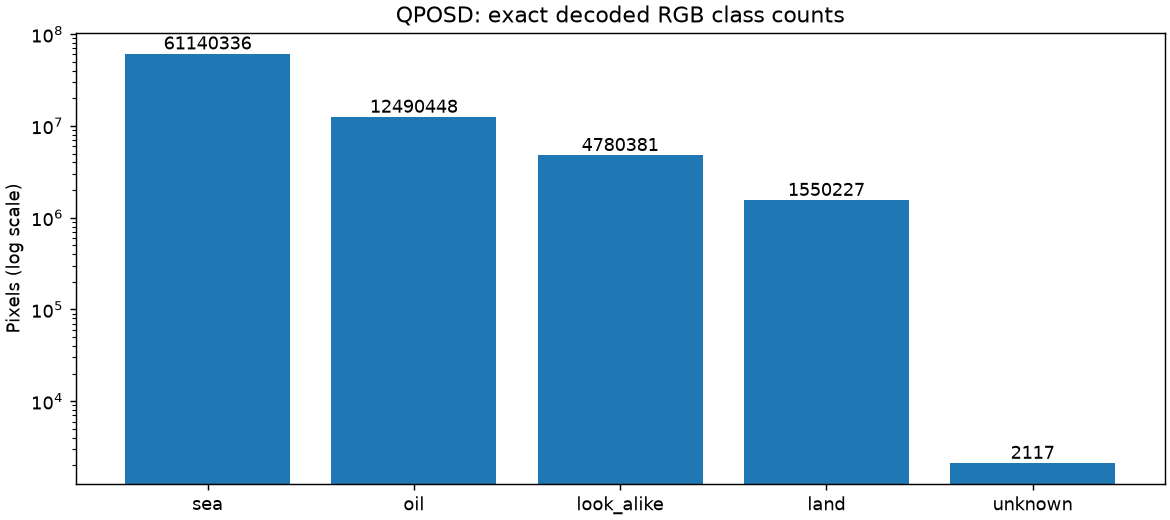

In [2]:
totals={name:0 for name in CLASS_NAMES}; unknown=0
for row in masks['masks']:
    raw=(ROOT/row['local_path']).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==row['sha256']
    with PILImage.open(io.BytesIO(raw)) as image: labels=decode_mask(np.asarray(image.convert('RGB')))
    for index,name in enumerate(CLASS_NAMES):
        count=int((labels==index).sum()); assert count==row['counts'][name]
        totals[name]+=count
    invalid=int((labels==255).sum()); assert invalid==row['unknown_pixels']; unknown+=invalid
assert totals==masks['totals'] and unknown==masks['unknown_pixels']
print('Số đếm đọc lại:', totals, '| Pixel bỏ qua:', unknown)
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
names=list(totals)+['unknown']; values=list(totals.values())+[unknown]
ax.bar(names,values); ax.set_yscale('log'); ax.set_ylabel('Pixels (log scale)')
ax.set_title('QPOSD: exact decoded RGB class counts')
for i,n in enumerate(values): ax.text(i,n,str(n),ha='center',va='bottom')
buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=130); display(Image(data=buf.getvalue())); plt.close(fig)


## Đối chiếu kích thước của 41 cặp

Đọc lại header đã tải và kiểm tra hash. Bộ đọc header riêng đã được đối chiếu
với `scipy.io.loadmat` trên ba tệp đầy đủ 7, 35, 40. Khớp kích thước là điều kiện
cần, chưa đủ để xác nhận đúng căn chỉnh hoặc nguồn cảnh độc lập.


In [3]:
table=['| Mẫu | Mảng T | Mask | Khớp |','|---:|---|---|---|']
for row in shapes['pairs']:
    raw=(ROOT/f"data/lookalike_sources/qposd_prefixes/image{row['number']}.prefix").read_bytes()
    assert hashlib.sha256(raw).hexdigest()==row['prefix_sha256']
    shape=first_array_shape(raw); assert shape==row['T_shape']
    match=shape[:2]==row['mask_shape']; assert match==row['spatial_shape_matches']
    table.append(f"| {row['number']} | {shape} | {row['mask_shape']} | {'Có' if match else 'Không'} |")
display(Markdown(chr(10).join(table)))
print('Khớp:', shapes['matching_pairs'], '| Lệch:', shapes['mismatching_pairs'])


| Mẫu | Mảng T | Mask | Khớp |
|---:|---|---|---|
| 1 | [1601, 1601, 9] | [1601, 1600] | Không |
| 2 | [1601, 1601, 9] | [1601, 1600] | Không |
| 3 | [1601, 1601, 9] | [1601, 1600] | Không |
| 4 | [2051, 2051, 9] | [2051, 2051] | Có |
| 5 | [1026, 1026, 9] | [1026, 1025] | Không |
| 6 | [1601, 1601, 9] | [1601, 1600] | Không |
| 7 | [521, 521, 9] | [521, 520] | Không |
| 8 | [2051, 2051, 9] | [2051, 2051] | Có |
| 9 | [1051, 1051, 9] | [1050, 1050] | Không |
| 10 | [2051, 2051, 9] | [2051, 2051] | Có |
| 11 | [1051, 1051, 9] | [1050, 1050] | Không |
| 12 | [1026, 1026, 9] | [1025, 1025] | Không |
| 13 | [2051, 2051, 9] | [2051, 2051] | Có |
| 14 | [2051, 2051, 9] | [2051, 2051] | Có |
| 15 | [2051, 2051, 9] | [2051, 2051] | Có |
| 16 | [1031, 1031, 9] | [1031, 1031] | Có |
| 17 | [1031, 1031, 9] | [1031, 1031] | Có |
| 18 | [1031, 1031, 9] | [1031, 1031] | Có |
| 19 | [1031, 1031, 9] | [1031, 1031] | Có |
| 20 | [1031, 1031, 9] | [1031, 1031] | Có |
| 21 | [1031, 1031, 9] | [1031, 1031] | Có |
| 22 | [1031, 1031, 9] | [1031, 1031] | Có |
| 23 | [1051, 1051, 9] | [1050, 1050] | Không |
| 24 | [1031, 1031, 9] | [1031, 1031] | Có |
| 25 | [1031, 1031, 9] | [1031, 1031] | Có |
| 26 | [1551, 1551, 9] | [1551, 1551] | Có |
| 27 | [1051, 1051, 9] | [1050, 1050] | Không |
| 28 | [2051, 2051, 9] | [2051, 2051] | Có |
| 29 | [1601, 1601, 9] | [1601, 1600] | Không |
| 30 | [1601, 1601, 9] | [1601, 1600] | Không |
| 31 | [1601, 1601, 9] | [1601, 1600] | Không |
| 32 | [2051, 2051, 9] | [2051, 2051] | Có |
| 33 | [1031, 1031, 9] | [1031, 1031] | Có |
| 34 | [1031, 1031, 9] | [1031, 1031] | Có |
| 35 | [771, 771, 9] | [771, 771] | Có |
| 36 | [1551, 1551, 9] | [1551, 1551] | Có |
| 37 | [1026, 1026, 9] | [1025, 1025] | Không |
| 38 | [1026, 1026, 9] | [1025, 1025] | Không |
| 39 | [1031, 1031, 9] | [1031, 1031] | Có |
| 40 | [521, 521, 9] | [521, 520] | Không |
| 41 | [1031, 1031, 9] | [1031, 1031] | Có |

Khớp: 24 | Lệch: 17


## Ba cặp đã tải đầy đủ

T11 chỉ được đổi thang log và giới hạn hiển thị theo phân vị 1–99% để nhìn ảnh.
Đó không phải bước chuẩn hóa cho mô hình. Ảnh và mask hiển thị riêng, không
resize hoặc overlay để che sai lệch. Ba mẫu chọn theo dung lượng nhỏ và nhóm
nhãn khác nhau, không phải mẫu ngẫu nhiên đại diện bộ dữ liệu.


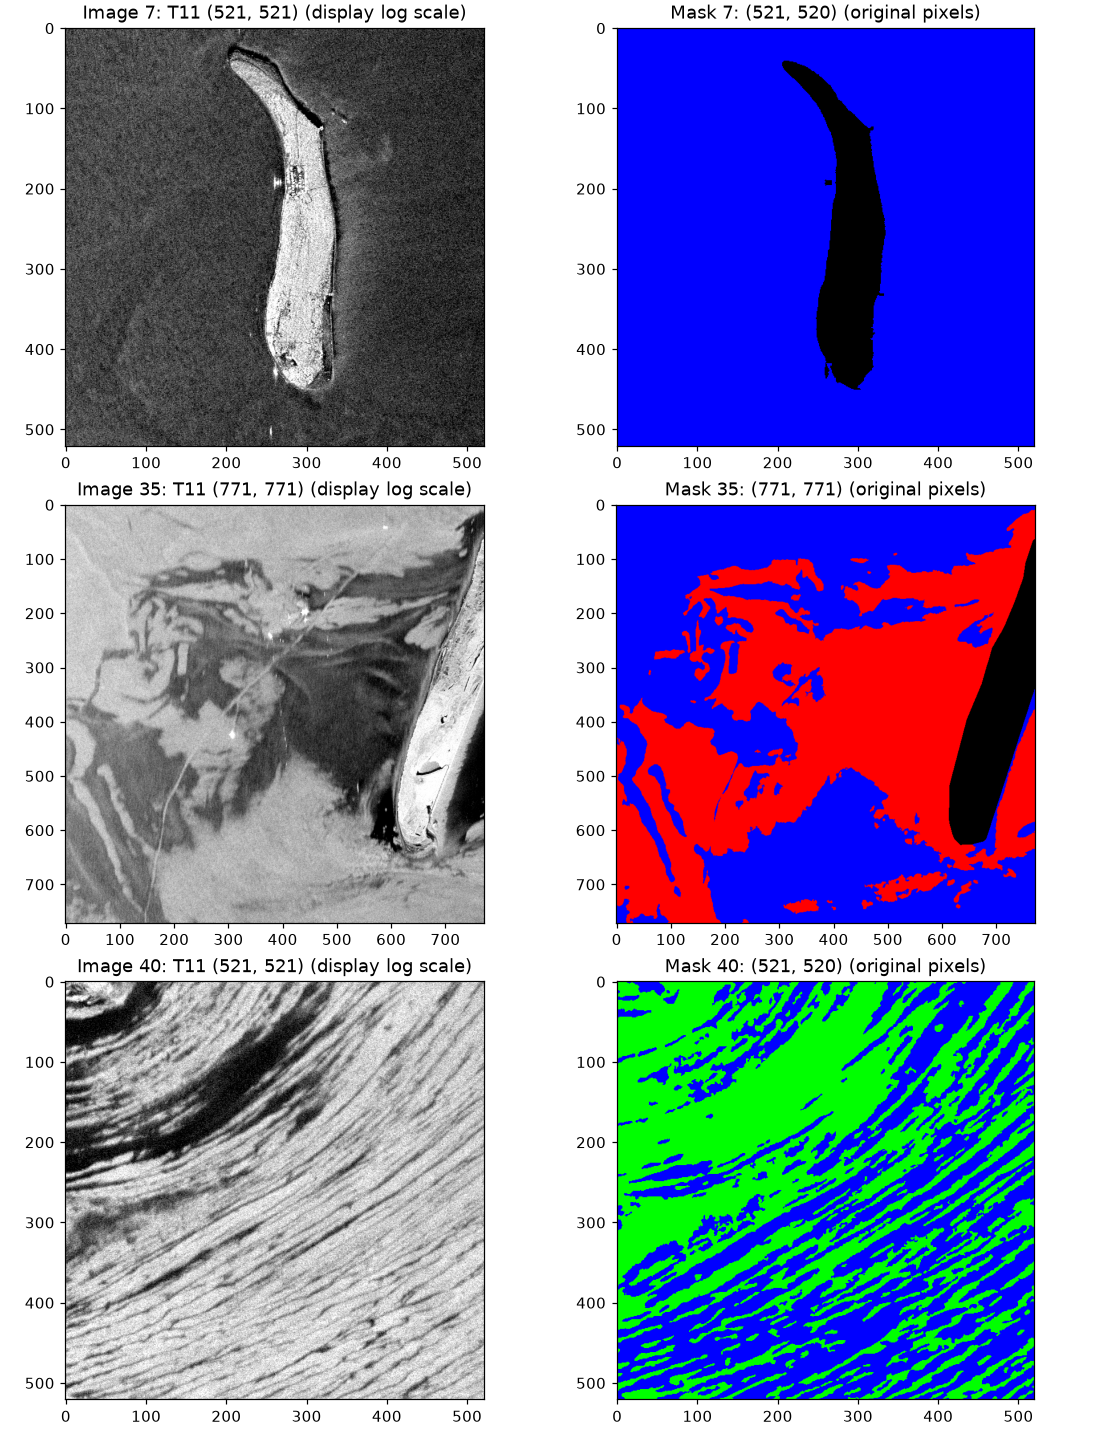

In [4]:
from scipy.io import loadmat
features=json.loads((ROOT/'docs/management/qposd_feature_audit.json').read_text())
fig,axes=plt.subplots(3,2,figsize=(10,13),layout='constrained')
for i,row in enumerate(features['pairs']):
    number=int(Path(row['member']).stem.replace('image',''))
    path=ROOT/'data/lookalike_sources/qposd_features'/Path(row['member']).name
    raw=path.read_bytes(); assert hashlib.sha256(raw).hexdigest()==row['sha256']
    T=loadmat(io.BytesIO(raw))['T']; assert list(T.shape)==row['variables']['T']['shape']
    maskrow=next(r for r in masks['masks'] if r['member']==row['mask_member'])
    mask=np.asarray(PILImage.open(ROOT/maskrow['local_path']).convert('RGB'))
    visible=10*np.log10(np.maximum(T[:,:,0],1e-12)); low,high=np.percentile(visible,[1,99])
    axes[i,0].imshow(visible,cmap='gray',vmin=low,vmax=high)
    axes[i,0].set_title(f'Image {number}: T11 {T.shape[:2]} (display log scale)')
    axes[i,1].imshow(mask); axes[i,1].set_title(f'Mask {number}: {mask.shape[:2]} (original pixels)')
buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=110); display(Image(data=buf.getvalue())); plt.close(fig)


## Kết luận của phép thẩm định

Không tự sửa mask để tăng điểm. Chưa dùng các cặp lệch kích thước để chấm F1.
Các cặp khớp vẫn cần kiểm tra căn chỉnh, ý nghĩa kênh, nguồn cảnh và cách chia
dữ liệu trước khi lựa chọn thuật toán. Notebook này chưa chạy phân lớp dầu/look-alike.
